<a href="https://colab.research.google.com/github/ssehnem/financial_ews/blob/main/TCC_Dow_Jones_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preparation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import shap
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, roc_curve, auc
from scipy.stats.mstats import winsorize

In [2]:
df = pd.read_csv('/content/drive/MyDrive/stockstcc2026/codestcc/data/dow_jones_data.csv', sep=',')

df.columns = ['date', 'value']
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(df.head())
print(df.dtypes)

        date  value
0 1914-12-31  54.63
1 1915-01-30  56.54
2 1915-02-27  55.02
3 1915-03-31  60.83
4 1915-04-30  71.78
date     datetime64[ns]
value           float64
dtype: object


In [3]:
df['return']     = df['value'].pct_change()
df['ma_3']       = df['value'].rolling(3).mean()
df['ma_12']      = df['value'].rolling(12).mean()
df['volatility'] = df['return'].rolling(6).std()
df['drawdown']   = (df['value'] / df['value'].cummax()) - 1

# EDA

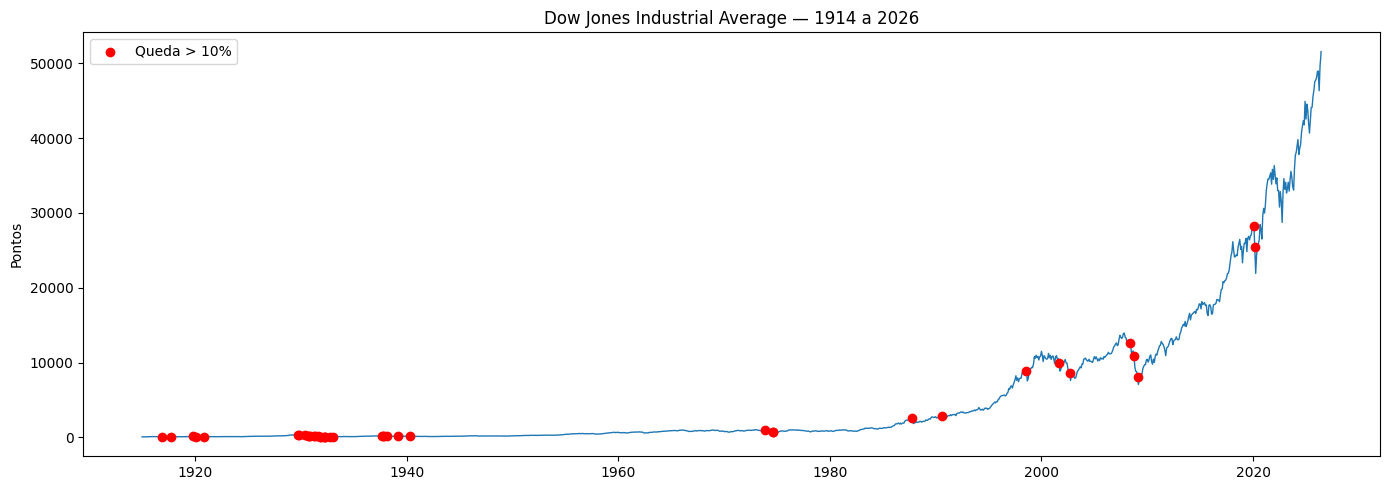

In [4]:
# Garantir que a coluna crash_next esteja definida caso tenha sido pulada anteriormente
if 'crash_next' not in df.columns:
    df['crash_next'] = (df['return'].shift(-1) < -0.10).astype(int)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['date'], df['value'], linewidth=1)

crashes = df[df['crash_next'] == 1]
ax.scatter(crashes['date'], crashes['value'],
           color='red', zorder=5, label='Queda > 10%')

ax.set_title('Dow Jones Industrial Average — 1914 a 2026')
ax.set_ylabel('Pontos')
ax.legend()
plt.tight_layout()
plt.savefig('djia_historico.png', dpi=150)
plt.show()

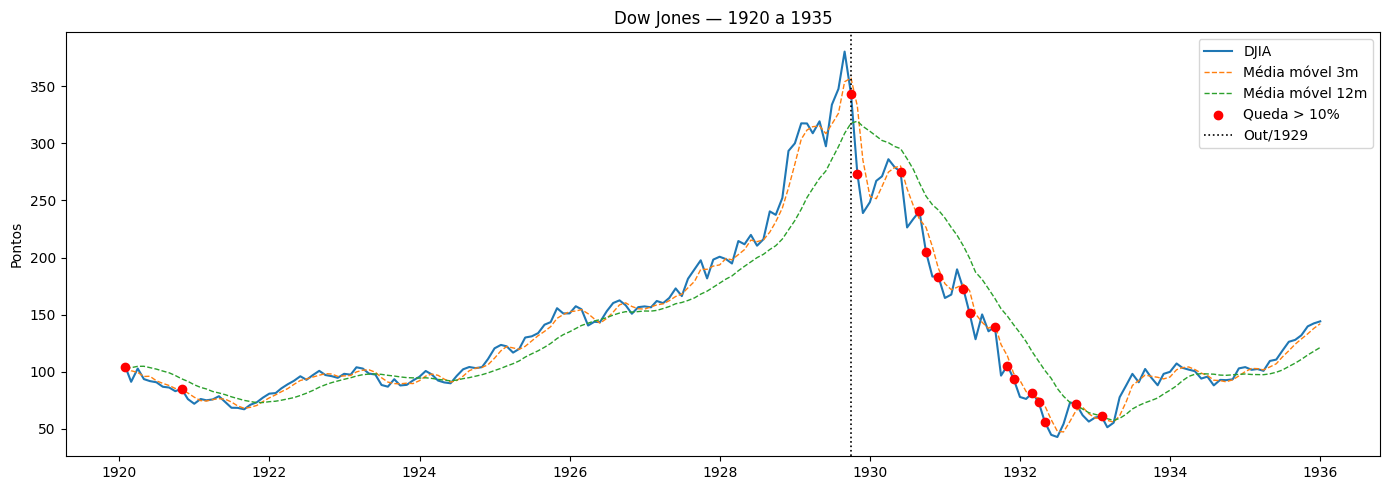

In [5]:
mask = (df['date'] >= '1920-01-01') & (df['date'] <= '1935-12-31')
df_crise = df[mask].copy()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_crise['date'], df_crise['value'], label='DJIA', linewidth=1.5)
ax.plot(df_crise['date'], df_crise['ma_3'],  label='Média móvel 3m', linestyle='--', linewidth=1)
ax.plot(df_crise['date'], df_crise['ma_12'], label='Média móvel 12m', linestyle='--', linewidth=1)

crashes = df_crise[df_crise['crash_next'] == 1]
ax.scatter(crashes['date'], crashes['value'], color='red', zorder=5, label='Queda > 10%')

ax.axvline(pd.Timestamp('1929-10-01'), color='black', linestyle=':', linewidth=1.2, label='Out/1929')

ax.set_title('Dow Jones — 1920 a 1935')
ax.set_ylabel('Pontos')
ax.legend()
plt.tight_layout()
plt.savefig('djia_1920_1935.png', dpi=150)
plt.show()

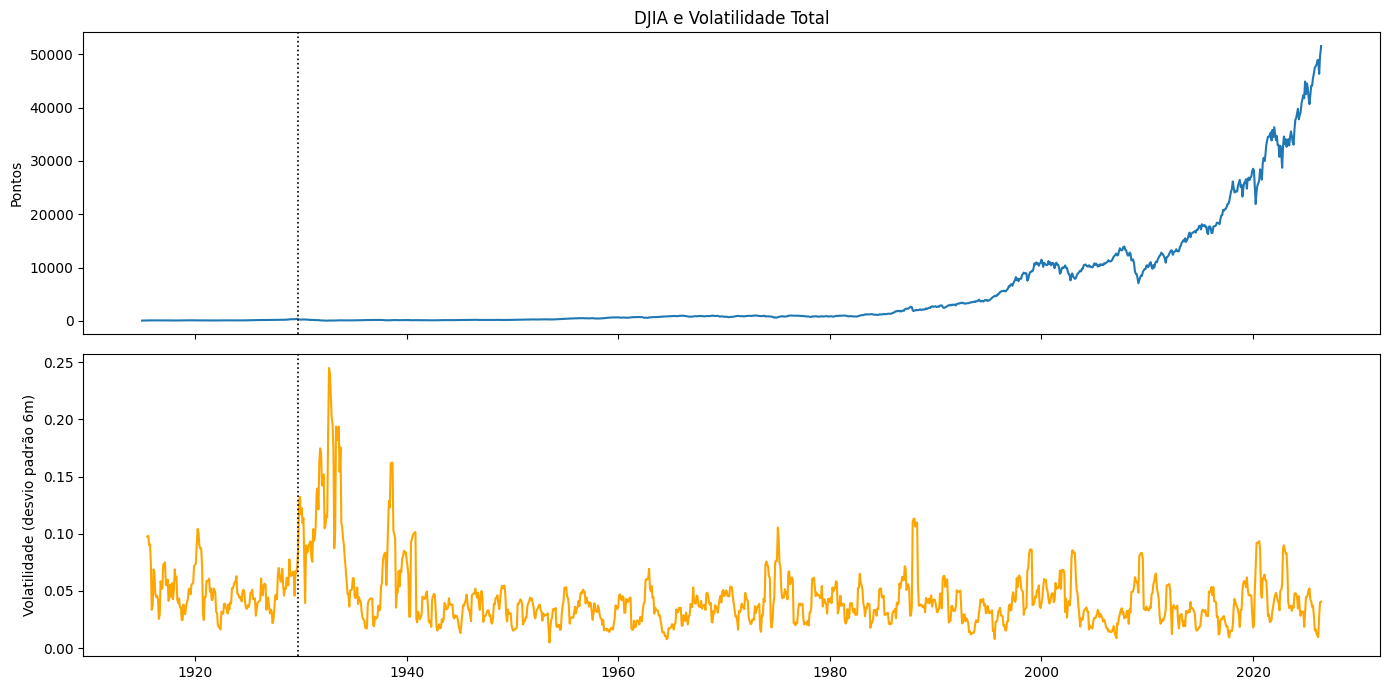

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Painel superior: preço
ax1.plot(df['date'], df['value'], linewidth=1.5)
ax1.set_ylabel('Pontos')
ax1.axvline(pd.Timestamp('1929-10-01'), color='black', linestyle=':', linewidth=1.2)
ax1.set_title('DJIA e Volatilidade Total')

# Painel inferior: volatilidade
ax2.plot(df['date'], df['volatility'], color='orange', linewidth=1.5)
ax2.set_ylabel('Volatilidade (desvio padrão 6m)')
ax2.axvline(pd.Timestamp('1929-10-01'), color='black', linestyle=':', linewidth=1.2)

plt.tight_layout()
plt.savefig('volatilidade_1929.png', dpi=150)
plt.show()

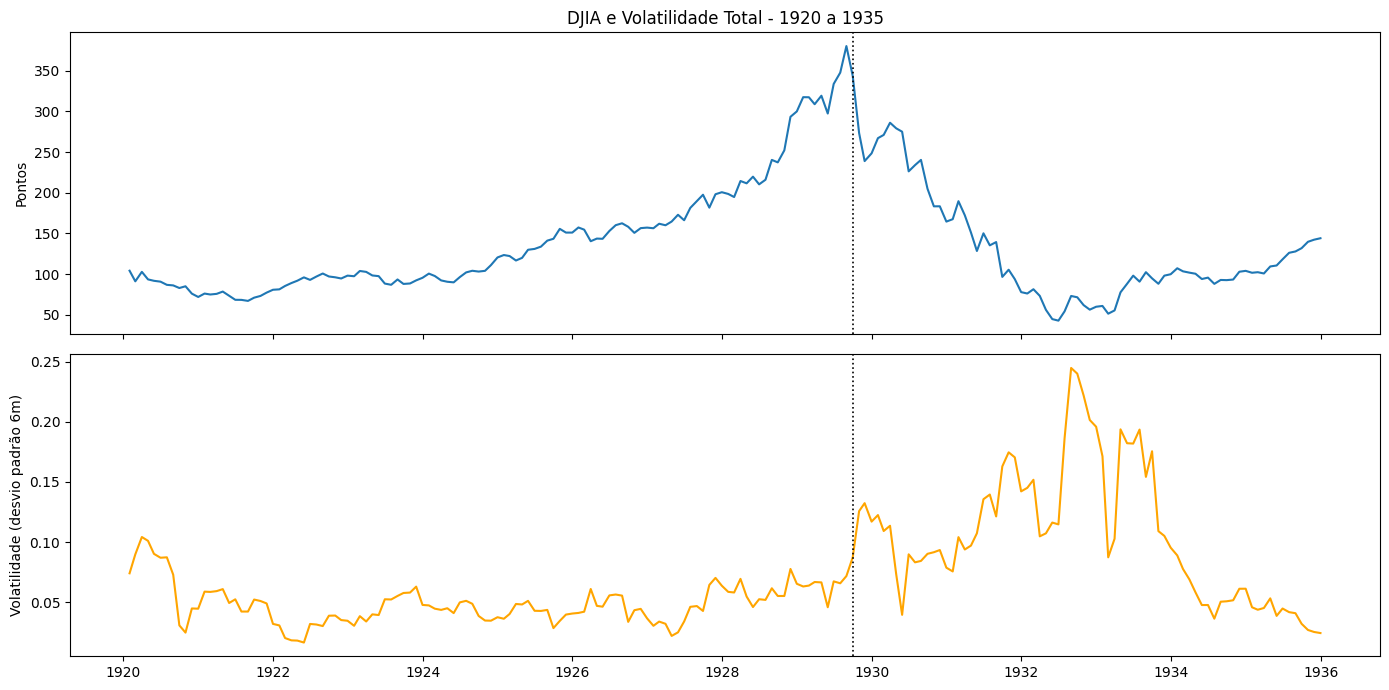

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Painel superior: preço
ax1.plot(df_crise['date'], df_crise['value'], linewidth=1.5)
ax1.set_ylabel('Pontos')
ax1.axvline(pd.Timestamp('1929-10-01'), color='black', linestyle=':', linewidth=1.2)
ax1.set_title('DJIA e Volatilidade Total - 1920 a 1935')

# Painel inferior: volatilidade
ax2.plot(df_crise['date'], df_crise['volatility'], color='orange', linewidth=1.5)
ax2.set_ylabel('Volatilidade (desvio padrão 6m)')
ax2.axvline(pd.Timestamp('1929-10-01'), color='black', linestyle=':', linewidth=1.2)

plt.tight_layout()
plt.savefig('volatilidade_1929.png', dpi=150)
plt.show()

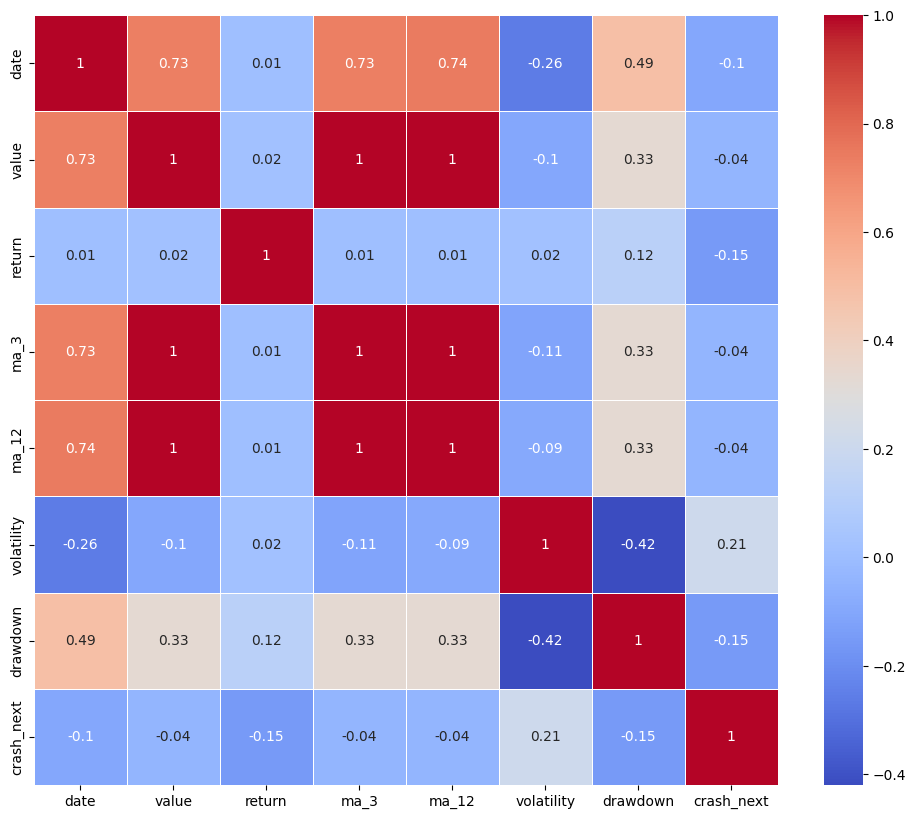

In [8]:
df_matrix = df

correlation_matrix = df.corr().round(2)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', ax=ax, linewidths=0.5)
plt.show()

# Predictive Modeling

In [9]:
df_jst = pd.read_csv('/content/drive/MyDrive/stockstcc2026/codestcc/data/JSTdatasetR6.csv')

# Filtra apenas os dados dos Estados Unidos, já que o Dow Jones é um índice americano
df_macro = df_jst[df_jst['country'] == 'USA'].copy()

# 2. Seleção das colunas de interesse
colunas_macro = [
    'year',
    'gdp',       # PIB
    'cpi',       # Inflação (Consumer Price Index)
    'stir',      # Taxa de juros de curto prazo
    'tloans',    # Total de empréstimos (Crédito)
    'ca'         # Current Account
]
df_macro = df_macro[colunas_macro]

# 3. Tratamento de Outliers (Winsorization a 1% e 99%)
for col in ['gdp', 'cpi', 'stir', 'tloans', 'ca']:
    df_macro[col] = winsorize(df_macro[col], limits=[0.01, 0.01])

# 4. Transformações (Taxas de Crescimento e Log)
df_macro['gdp_growth'] = df_macro['gdp'].pct_change()
df_macro['inflation_rate'] = df_macro['cpi'].pct_change()
df_macro['credit_growth'] = df_macro['tloans'].pct_change()

features_macro_derivadas = ['gdp_growth', 'inflation_rate', 'credit_growth', 'stir', 'ca']
for col in features_macro_derivadas:
    df_macro[f'{col}_lag1'] = df_macro[col].shift(1)

# 5. Alinhamento de Frequência (Dow Jones é mensal, JST é anual)
df['year'] = df['date'].dt.year

# 7. Merge e Exclusão de Guerras
df = df.merge(df_macro[['year'] + [f'{col}_lag1' for col in features_macro_derivadas]],
              on='year',
              how='left')

# Exclusão do período da Segunda Guerra Mundial
df = df[(df['year'] < 1939) | (df['year'] > 1945)]

# Atualização da lista de features para o modelo
features_macro = [f'{col}_lag1' for col in features_macro_derivadas]

Total de instâncias válidas: 1178
Crashes futuros (3 meses) no conjunto: 92 (7.8%)



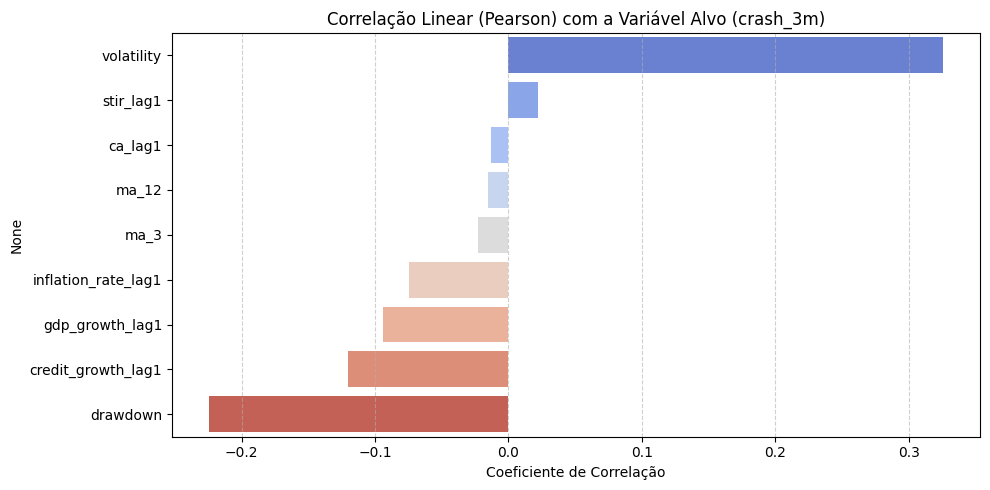

In [10]:
for col in features_macro:
    if col not in df.columns:
        matching_cols = [c for c in df.columns if c.startswith(col + '_')]
        if matching_cols:
            df = df.rename(columns={matching_cols[-1]: col})

# ===== 1. DEFINIÇÃO DA VARIÁVEL ALVO (TARGET) =====
horizon = 3  # Prever crash nos próximos 3 meses

# Retorno futuro mínimo (excluindo o mês atual)
future_returns = df['return'].shift(-1)
df['future_min_return'] = future_returns[::-1].rolling(window=horizon, min_periods=1).min()[::-1]

# Define classe 1 (Crash) se a queda for pior que -10% e nomeia de forma exclusiva
df['crash_3m'] = (df['future_min_return'] < -0.10).astype(int)

# ===== 2. INTEGRAÇÃO DE DADOS MACROECONÔMICOS =====
features_tecnicas = ['ma_3', 'ma_12', 'volatility', 'drawdown']

features = features_tecnicas + features_macro

# Cria dataset final removendo NaNs devido ao cálculo das médias/shifts
df_model = df[features + ['crash_3m']].dropna().copy()

X = df_model[features]
y = df_model['crash_3m']

print(f"Total de instâncias válidas: {len(df_model)}")
print(f"Crashes futuros (3 meses) no conjunto: {y.sum()} ({y.mean()*100:.1f}%)\n")

# ===== 3. CORRELAÇÃO DAS VARIÁVEIS COM O ALVO =====
target_corr = df_model[features + ['crash_3m']].corr()['crash_3m'].drop('crash_3m').sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=target_corr.values, y=target_corr.index, palette='coolwarm', hue=target_corr.index, legend=False)
plt.title('Correlação Linear (Pearson) com a Variável Alvo (crash_3m)')
plt.xlabel('Coeficiente de Correlação')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [11]:
# TimeSeriesSplit com 'gap' previne vazamento de dados de rótulos sobrepostos
tscv = TimeSeriesSplit(n_splits=5, gap=horizon)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=200, max_depth=5, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

auc_scores = {name: [] for name in models}
oof_roc_data = {name: {'y_true': [], 'y_pred_proba': []} for name in models}

print("=== Walk-Forward Cross-Validation (Métrica: AUROC) ===\n")

for name, model in models.items():
    for train_idx, test_idx in tscv.split(X):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        if name == 'Gradient Boosting':
            weights = compute_sample_weight(class_weight='balanced', y=y_train)
            model.fit(X_train_scaled, y_train, sample_weight=weights)
        else:
            model.fit(X_train_scaled, y_train)

        y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

        if len(np.unique(y_test)) > 1:
            auc_val = roc_auc_score(y_test, y_pred_proba)
            auc_scores[name].append(auc_val)

            oof_roc_data[name]['y_true'].extend(y_test.values)
            oof_roc_data[name]['y_pred_proba'].extend(y_pred_proba)

    mean_auc = np.mean(auc_scores[name])
    std_auc = np.std(auc_scores[name])
    print(f"{name}: AUROC Médio = {mean_auc:.3f} | Desvio Padrão = {std_auc:.3f}")

=== Walk-Forward Cross-Validation (Métrica: AUROC) ===

Logistic Regression: AUROC Médio = 0.593 | Desvio Padrão = 0.173
Random Forest: AUROC Médio = 0.627 | Desvio Padrão = 0.144
Gradient Boosting: AUROC Médio = 0.475 | Desvio Padrão = 0.129


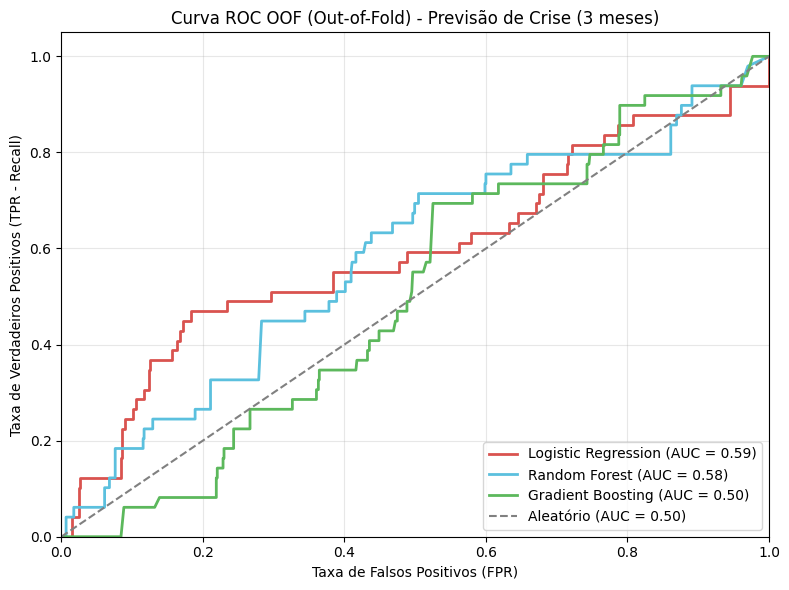

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

cores = ['#d9534f', '#5bc0de', '#5cb85c']

for (name, data), color in zip(oof_roc_data.items(), cores):
    y_true = data['y_true']
    y_proba = data['y_pred_proba']

    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)

    ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')

ax.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Aleatório (AUC = 0.50)')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Taxa de Falsos Positivos (FPR)')
ax.set_ylabel('Taxa de Verdadeiros Positivos (TPR - Recall)')
ax.set_title('Curva ROC OOF (Out-of-Fold) - Previsão de Crise (3 meses)')
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('curva_roc_modelos.png', dpi=150)
plt.show()

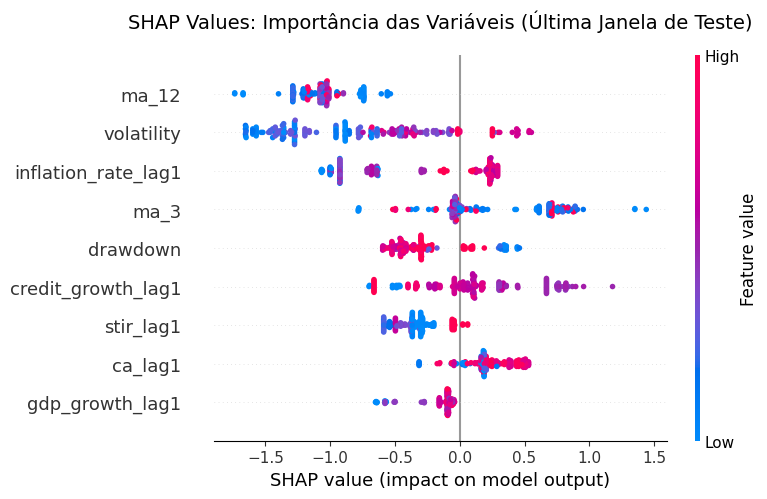

In [13]:
gb_model = models['Gradient Boosting']

# Para a explicação de SHAP sem vazamento de dados, convertemos o X_test_scaled para DataFrame mantendo as colunas corretas (features)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=features)

# Inicializa o explicador baseado em árvores utilizando o modelo treinado
explainer = shap.TreeExplainer(gb_model)

# Calcula os valores SHAP na amostra de teste escalonada
shap_values = explainer.shap_values(X_test_scaled_df)

# Gera o gráfico de impacto das variáveis
plt.figure(figsize=(10, 6))

shap.summary_plot(shap_values, X_test_scaled_df, feature_names=features, show=False)
plt.title("SHAP Values: Importância das Variáveis (Última Janela de Teste)", fontsize=14, pad=20)
plt.tight_layout()
plt.savefig('shap_summary_plot.png', dpi=150)
plt.show()

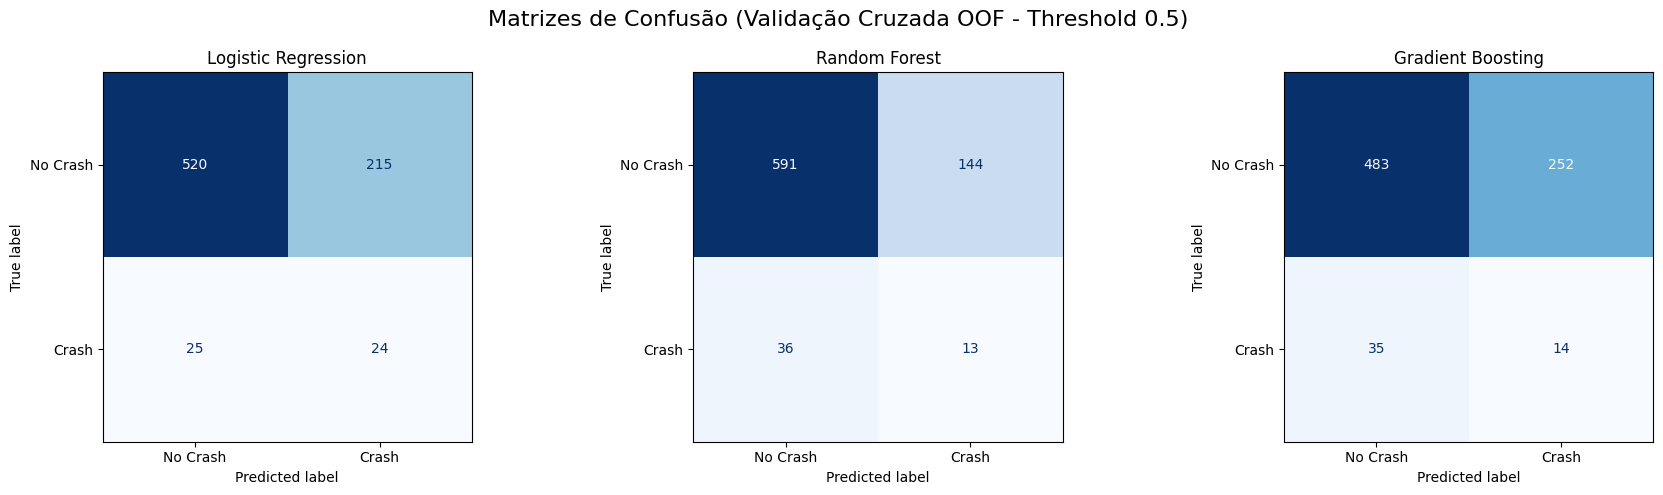

In [17]:
# Gerar Matriz de Confusão para as previsões Out-Of-Fold (OOF) de todos os modelos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, data) in zip(axes, oof_roc_data.items()):
    y_true = data['y_true']
    y_pred_proba = np.array(data['y_pred_proba'])

    y_pred = (y_pred_proba >= 0.5).astype(int)

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Crash', 'Crash'])

    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}')

plt.suptitle('Matrizes de Confusão (Validação Cruzada OOF - Threshold 0.5)', fontsize=16)
plt.tight_layout()
plt.savefig('confusion_matrix_modelos.png', dpi=150)
plt.show()

In [15]:
print("=== Cálculo dos Limiares Ótimos de Decisão (G-Mean) ===\n")

optimal_thresholds = {}

for name, data in oof_roc_data.items():
    y_true = np.array(data['y_true'])
    y_proba = np.array(data['y_pred_proba'])

    # Calcula os pontos da curva ROC
    fpr, tpr, thresholds = roc_curve(y_true, y_proba)

    # G-Mean calcula a média geométrica entre Sensibilidade (TPR) e Especificidade (1 - FPR)
    gmeans = np.sqrt(tpr * (1 - fpr))

    # Localiza o índice do maior G-Mean
    ix = np.argmax(gmeans)
    best_thresh = thresholds[ix]

    optimal_thresholds[name] = best_thresh
    print(f"{name}:")
    print(f"  - Limiar Ótimo: {best_thresh:.4f}")
    print(f"  - G-Mean Máximo: {gmeans[ix]:.3f}")
    print(f"  - Sensibilidade (Recall): {tpr[ix]:.3f}")
    print(f"  - Especificidade: {1 - fpr[ix]:.3f}\n")

=== Cálculo dos Limiares Ótimos de Decisão (G-Mean) ===

Logistic Regression:
  - Limiar Ótimo: 0.6275
  - G-Mean Máximo: 0.619
  - Sensibilidade (Recall): 0.469
  - Especificidade: 0.816

Random Forest:
  - Limiar Ótimo: 0.3247
  - G-Mean Máximo: 0.596
  - Sensibilidade (Recall): 0.633
  - Especificidade: 0.562

Gradient Boosting:
  - Limiar Ótimo: 0.1444
  - G-Mean Máximo: 0.574
  - Sensibilidade (Recall): 0.694
  - Especificidade: 0.475



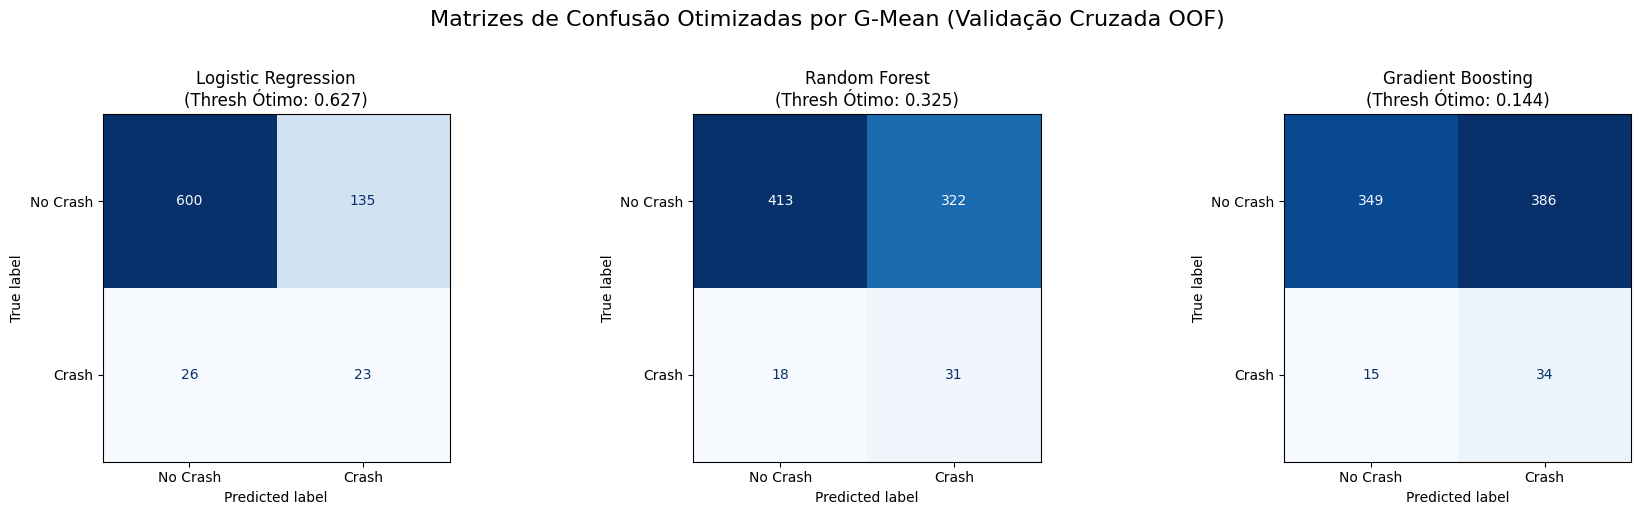

In [16]:
# Gerar novas Matrizes de Confusão baseadas nos limiares ótimos calculados
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, data) in zip(axes, oof_roc_data.items()):
    y_true = data['y_true']
    y_pred_proba = np.array(data['y_pred_proba'])

    # Aplica o limiar ótimo específico de cada modelo
    thresh = optimal_thresholds[name]
    y_pred = (y_pred_proba >= thresh).astype(int)

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Crash', 'Crash'])

    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\n(Thresh Ótimo: {thresh:.3f})')

plt.suptitle('Matrizes de Confusão Otimizadas por G-Mean (Validação Cruzada OOF)', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrix_otimizada.png', dpi=150)
plt.show()